<a href="https://colab.research.google.com/github/LakinduSachin/CR-CM-Coursework/blob/main/test_01_CR_%26_CM_Course_work.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd, numpy as np, yfinance as yf
import matplotlib.pyplot as plt, seaborn as sns
from datetime import date

In [ ]:
RETRIEVAL_DATE = date.today().isoformat()
url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'
sp500_df = pd.read_html(url, storage_options={"User-Agent": "Mozilla/5.0"})[0]

In [ ]:
# yfinance uses '-' not '.' (BRK.B -> BRK-B); apply to the sector index too so they match
sp500_df['Symbol'] = sp500_df['Symbol'].str.replace('.', '-', regex=False)
tickers = sp500_df['Symbol'].tolist()
sectors = sp500_df.set_index('Symbol')['GICS Sector']     # kept for Task 3.2.1
print('Tickers:', len(tickers), '| retrieved on', RETRIEVAL_DATE)

Tickers: 503 | retrieved on 2026-11-14


In [ ]:
# Cell 2 — download Adj Close + Close + Volume, correct window, save a snapshot
start = '2021-01-01'
end = '2025-01-01'    # END is EXCLUSIVE -> last day 2024-12-31

raw = yf.download(tickers + ['^GSPC'], start=START, end=END,
                  auto_adjust=False, actions=False)

print('Fields:', list(raw.columns.get_level_values(0).unique()))
adj   = raw['Adj Close']     # -> weekly returns & beta
close = raw['Close']         # -> Monetary (brief: Close x Volume)
vol   = raw['Volume']        # -> R, F, M

raw.to_parquet('sp500_raw_2021_2025.parquet')   # reproducible data snapshot
print('Daily shape:', adj.shape)

[*********************100%***********************]  504 of 504 completed
ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['FDXF', 'HONA', 'VYLR', 'SNDK', 'Q']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Fields: ['Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume']
Daily shape: (1005, 504)


In [ ]:
# Cell 3 — validation / "Clean" step   [Week 11 KDD: Select-Clean-Transform; replaces ffill/bfill]
bmk_adj      = adj['^GSPC']
shares_adj   = adj.drop(columns='^GSPC')
shares_close = close.drop(columns='^GSPC')
shares_vol   = vol.drop(columns='^GSPC')

n_sessions = len(shares_adj)
val = pd.DataFrame({
    'n_obs':              shares_adj.notna().sum(),
    'n_missing':          shares_adj.isna().sum(),
    'nonpositive_adj':   (shares_adj   <= 0).sum(),
    'nonpositive_close': (shares_close <= 0).sum(),
    'bad_volume':        ((shares_vol < 0) | shares_vol.isna()).sum(),
})
val['coverage'] = val['n_obs'] / n_sessions

print('Duplicate dates:', adj.index.duplicated().sum())
print('Trading sessions in window:', n_sessions)
val.sort_values('coverage').head()

Duplicate dates: 0
Trading sessions in window: 1005


,n_obs,n_missing,nonpositive_adj,nonpositive_close,bad_volume,coverage
Ticker,,,,,,
VYLR,0,1005,0,0,1005,0.0
SNDK,0,1005,0,0,1005,0.0
HONA,0,1005,0,0,1005,0.0
Q,0,1005,0,0,1005,0.0
FDXF,0,1005,0,0,1005,0.0


In [ ]:
# Cell 4 — observation date + exclusions   [snapshot-date idea from RFM_Kmeans / RFM_Yahoofin]
obs_date = bmk_adj.last_valid_index()
print('Observation date:', obs_date.date())

MIN_COVERAGE = 0.95                              # your judgement call -> justify in report
has_obs     = shares_adj.loc[obs_date].notna()
enough_hist = val['coverage'] >= MIN_COVERAGE
keep        = has_obs & enough_hist

reason = np.where(~has_obs.values, 'no data on observation date', 'short history (<95% coverage)')
exclusion_log = val.loc[~keep].assign(reason=reason[~keep.values])
print('Kept:', int(keep.sum()), '| Excluded:', int((~keep).sum()))
exclusion_log

Observation date: 2024-12-31
Kept: 489 | Excluded: 14


,n_obs,n_missing,nonpositive_adj,nonpositive_close,bad_volume,coverage,reason
Ticker,,,,,,,
APP,935,70,0,0,70,0.930348,short history (<95% coverage)
CEG,742,263,0,0,263,0.738308,short history (<95% coverage)
COIN,936,69,0,0,69,0.931343,short history (<95% coverage)
FDXF,0,1005,0,0,1005,0.000000,no data on observation date
GEHC,513,492,0,0,492,0.510448,short history (<95% coverage)
GEV,193,812,0,0,812,0.192040,short history (<95% coverage)
HONA,0,1005,0,0,1005,0.000000,no data on observation date
HOOD,862,143,0,0,143,0.857711,short history (<95% coverage)
Q,0,1005,0,0,1005,0.000000,no data on observation date


In [ ]:
# Cell 5 — weekly returns + alignment   [sp500.ipynb calculate_weekly_returns]
valid = keep[keep].index.tolist()
weekly_adj = shares_adj[valid].resample('W-FRI').last()
weekly_bmk = bmk_adj.resample('W-FRI').last()

weekly_ret = weekly_adj.pct_change(fill_method=None).iloc[1:-1]   # drop incomplete first & last weeks
bmk_ret    = weekly_bmk.pct_change(fill_method=None).iloc[1:-1]
print('Valid shares:', len(valid), '| Aligned weeks:', len(bmk_ret))

Valid shares: 489 | Aligned weeks: 207


In [ ]:
# Cell 6 — risk/return features: mean weekly return (1.3.1) + weekly beta (1.3.2)
# [reuses sp500.ipynb calculate_weekly_beta; beta = Cov/Var from the Beta explainer]
def risk_return_features(weekly_ret, bmk_ret, min_weeks=52):
    rows = []
    for s in weekly_ret.columns:
        paired = (pd.concat([weekly_ret[s].rename('share'),
                             bmk_ret.rename('mkt')], axis=1)
                    .replace([np.inf, -np.inf], np.nan)
                    .dropna())                       # pairwise aligned weeks only
        var = paired['mkt'].var(ddof=1)
        beta = (paired['share'].cov(paired['mkt']) / var
                if (len(paired) >= min_weeks and var > 0) else np.nan)
        rows.append({
            'Share': s,
            'MeanWeeklyReturn': weekly_ret[s].mean(),   # arithmetic mean (1.3.1)
            'Beta': beta,                               # Cov/Var (1.3.2)
            'AlignedWeeks': len(paired),
        })
    return pd.DataFrame(rows).set_index('Share')

rr = risk_return_features(weekly_ret, bmk_ret)
print('Aligned weeks (min/median/max):',
      rr.AlignedWeeks.min(), int(rr.AlignedWeeks.median()), rr.AlignedWeeks.max())
print('Betas with NaN:', rr.Beta.isna().sum())
rr.describe().round(4)

Aligned weeks (min/median/max): 202 207 207
Betas with NaN: 0


,MeanWeeklyReturn,Beta,AlignedWeeks
count,489.0000,489.0000,489.0000
mean,0.0029,0.9736,206.9898
std,0.0026,0.4062,0.2261
min,-0.0045,0.0555,202.0000
25%,0.0012,0.6667,207.0000
50%,0.0026,0.9480,207.0000
75%,0.0042,1.1792,207.0000
max,0.0178,3.7786,207.0000


,MeanWeeklyReturn,Beta,AlignedWeeks
Share,,,
GIS,0.001522,0.055453,207
SJM,0.000804,0.175579,207
MRK,0.002132,0.198287,207


,MeanWeeklyReturn,Beta,AlignedWeeks
Share,,,
COHR,0.003887,2.139305,207
XYZ,-0.001554,2.504520,207
CVNA,0.010964,3.778560,207


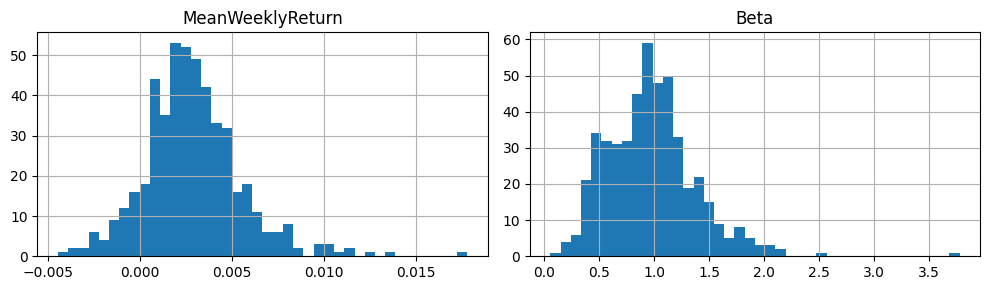

In [ ]:
# Cell 7 — sanity check the features
display(rr.sort_values('Beta').head(3))      # lowest-beta (defensive) shares
display(rr.sort_values('Beta').tail(3))      # highest-beta (aggressive) shares
rr[['MeanWeeklyReturn','Beta']].hist(bins=40, figsize=(10,3)); plt.tight_layout(); plt.show()

In [ ]:
# Cell 8 — adapted RFM (1.4): high-volume days, per share, pinned to obs_date
# [logic from RFM_Yahoofin: threshold = volume > 2x mean of preceding 20 sessions]
def rfm_features(close_df, vol_df, obs_date, lookback=60, base=20, mult=2.0):
    rows = []
    for s in close_df.columns:
        df = (pd.concat([close_df[s].rename('Close'),
                         vol_df[s].rename('Volume')], axis=1)
                .loc[:obs_date].dropna())
        if len(df) < base + lookback:                 # need 20 baseline + 60 window
            rows.append({'Share': s, 'Recency': np.nan,
                         'Frequency': np.nan, 'Monetary': np.nan}); continue

        base_mean = df['Volume'].shift(1).rolling(base).mean()   # preceding 20, excl. today
        high = df['Volume'] > mult * base_mean                   # high-volume flag per day

        hv_days = df.index[high.fillna(False)]                   # ALL history
        recency = (obs_date.date() - hv_days[-1].date()).days if len(hv_days) else np.nan

        recent = df.tail(lookback)                               # latest 60 sessions
        frequency = int(high.loc[recent.index].sum())
        monetary  = float((recent['Close'] * recent['Volume']).sum())

        rows.append({'Share': s, 'Recency': recency,
                     'Frequency': frequency, 'Monetary': monetary})
    return pd.DataFrame(rows).set_index('Share')

rfm = rfm_features(shares_close[valid], shares_vol[valid], obs_date)
print('No high-volume event (Recency NaN):', int(rfm['Recency'].isna().sum()))
rfm.describe().round(2)

No high-volume event (Recency NaN): 0


,Recency,Frequency,Monetary
count,489.00,489.00,4.890000e+02
mean,20.37,2.99,3.925106e+10
std,21.29,1.33,1.287563e+11
min,4.00,0.00,1.297483e+09
25%,11.00,2.00,1.025033e+10
50%,11.00,3.00,1.665860e+10
75%,15.00,4.00,3.201227e+10
max,222.00,8.00,1.847697e+12


In [ ]:
# Cell 9 — worked RFM example for one share (required evidence, 1.5)
s = 'AAPL'
df = (pd.concat([shares_close[s].rename('Close'), shares_vol[s].rename('Volume')], axis=1)
        .loc[:obs_date].dropna())
base_mean = df['Volume'].shift(1).rolling(20).mean()
df['Thresh'] = 2 * base_mean
df['High']   = df['Volume'] > df['Thresh']
print('Observation date:', obs_date.date())
print('Latest high-volume day:', df.index[df['High']][-1].date())
print('Recency (calendar days):', (obs_date.date() - df.index[df['High']][-1].date()).days)
print('Frequency (last 60):', int(df['High'].tail(60).sum()))
print('Monetary (last 60): $%.3e' % (df['Close'].tail(60) * df['Volume'].tail(60)).sum())
df.tail(5)[['Close','Volume','Thresh','High']]

Observation date: 2024-12-31
Latest high-volume day: 2024-12-20
Recency (calendar days): 11
Frequency (last 60): 2
Monetary (last 60): $6.233e+11


,Close,Volume,Thresh,High
Date,,,,
2024-12-24,258.200012,23234700,100816960.0,False
2024-12-26,259.019989,27237100,94125150.0,False
2024-12-27,255.589996,42355300,92250240.0,False
2024-12-30,252.199997,35557500,93135930.0,False
2024-12-31,250.419998,39480700,93843540.0,False


In [ ]:
# Cell 10 — two separate matrices, skew check, log1p(M), standardise  [brief 2.1]
from sklearn.preprocessing import StandardScaler

# common valid set = complete in BOTH matrices (here all 489)
common = rr.dropna(subset=['Beta']).index.intersection(rfm.dropna().index)
print('Common valid shares:', len(common))

# --- inspect skew BEFORE transforming ---
raw = rfm.loc[common, ['Recency','Frequency','Monetary']].copy()
raw['MeanWeeklyReturn'] = rr.loc[common, 'MeanWeeklyReturn']
raw['Beta']             = rr.loc[common, 'Beta']
print('\nSkew (raw):'); print(raw.skew().round(2))

# --- Matrix A: risk / return ---
A_raw = rr.loc[common, ['MeanWeeklyReturn','Beta']]
A = pd.DataFrame(StandardScaler().fit_transform(A_raw), index=common, columns=A_raw.columns)

# --- Matrix B: trading activity, log1p on M (brief requirement) ---
B_raw = rfm.loc[common, ['Recency','Frequency','Monetary']].copy()
B_raw['Monetary'] = np.log1p(B_raw['Monetary'])
print('\nSkew of log1p(Monetary):', round(B_raw['Monetary'].skew(), 2))
B = pd.DataFrame(StandardScaler().fit_transform(B_raw), index=common,
                 columns=['Recency','Frequency','logMonetary'])

print('\nMatrix A (risk/return):', A.shape, '| Matrix B (RFM):', B.shape)
A.describe().round(2)

Common valid shares: 489

Skew (raw):
Recency              3.66
Frequency            0.43
Monetary            11.72
MeanWeeklyReturn     0.86
Beta                 1.11
dtype: float64

Skew of log1p(Monetary): 1.09

Matrix A (risk/return): (489, 2) | Matrix B (RFM): (489, 3)


,MeanWeeklyReturn,Beta
count,489.00,489.00
mean,0.00,0.00
std,1.00,1.00
min,-2.77,-2.26
25%,-0.64,-0.76
50%,-0.09,-0.06
75%,0.51,0.51
max,5.64,6.91


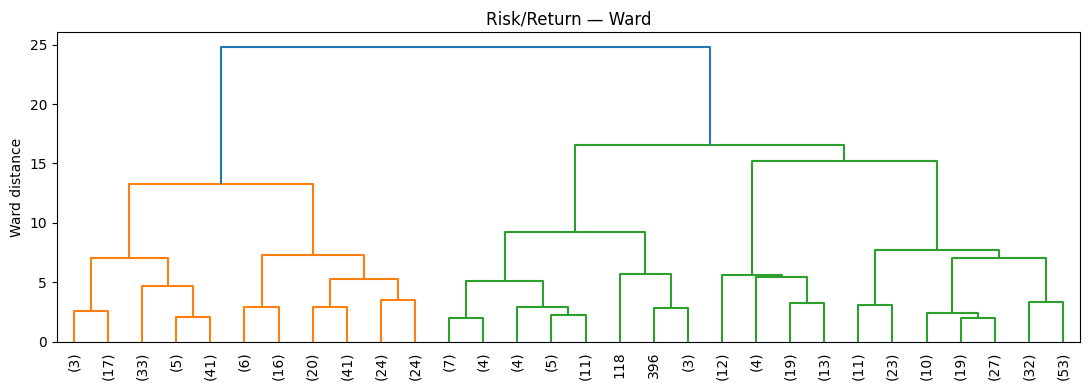

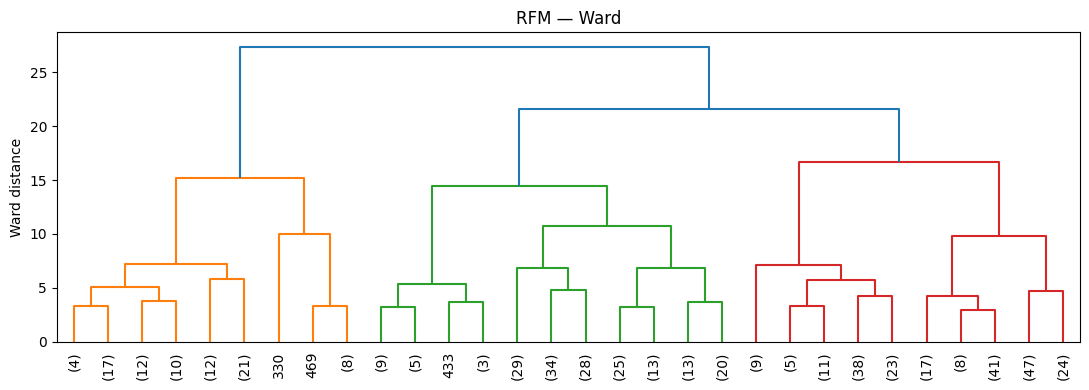

In [ ]:
# Cell 11 — one dendrogram per matrix (Ward, Euclidean)  [brief 2.2]
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

for X, title, fn in [(A.values, 'Risk/Return — Ward', 'dendro_A.png'),
                     (B.values, 'RFM — Ward',          'dendro_B.png')]:
    Z = linkage(X, method='ward')          # Ward linkage on standardised features
    plt.figure(figsize=(11, 4))
    dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90)  # top of tree (489 leaves is unreadable)
    plt.title(title); plt.ylabel('Ward distance'); plt.tight_layout()
    plt.savefig(fn, dpi=150); plt.show()

In [ ]:
# Cell 12 — k-selection diagnostics for BOTH algorithms, k = 2..8  [brief 2.2 & 2.3]
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

def diagnostics(X, label):
    Z = linkage(X, method='ward')
    rows = []
    for k in range(2, 9):
        km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)   # seed + multi-init
        ward = fcluster(Z, t=k, criterion='maxclust')
        rows.append({
            'k': k,
            'KM_silhouette':   round(silhouette_score(X, km.labels_), 3),
            'KM_inertia':      round(km.inertia_, 1),
            'KM_min_size':     int(np.bincount(km.labels_).min()),
            'Ward_silhouette': round(silhouette_score(X, ward), 3),
            'Ward_min_size':   int(np.bincount(ward)[1:].min()),
        })
    print(f'\n===== {label} ====='); print(pd.DataFrame(rows).to_string(index=False))

diagnostics(A.values, 'Matrix A (risk/return)')
diagnostics(B.values, 'Matrix B (RFM)')


===== Matrix A (risk/return) =====
 k  KM_silhouette  KM_inertia  KM_min_size  Ward_silhouette  Ward_min_size
 2          0.386       626.9          144            0.288            230
 3          0.327       465.6          120            0.279             36
 4          0.326       374.5           41            0.291             36
 5          0.339       312.4           28            0.312             36
 6          0.330       267.7           15            0.312              5
 7          0.355       229.7           16            0.292              5
 8          0.355       196.3            5            0.279              5

===== Matrix B (RFM) =====
 k  KM_silhouette  KM_inertia  KM_min_size  Ward_silhouette  Ward_min_size
 2          0.424      1073.7           68            0.370             86
 3          0.325       802.4           63            0.260             86
 4          0.341       613.9           61            0.250             86
 5          0.356       521.6       

In [ ]:
# Cell 13 — fit the 4 baseline solutions at the chosen k  [brief 2.2 + 2.3]
from sklearn.cluster import AgglomerativeClustering
K_A, K_B = 3, 3                      # change here if you revise your choice

labels = pd.DataFrame(index=common)
labels['A_KM']   = KMeans(K_A, n_init=10, random_state=42).fit_predict(A.values)
labels['A_Ward'] = AgglomerativeClustering(K_A, linkage='ward').fit_predict(A.values)
labels['B_KM']   = KMeans(K_B, n_init=10, random_state=42).fit_predict(B.values)
labels['B_Ward'] = AgglomerativeClustering(K_B, linkage='ward').fit_predict(B.values)

for col in labels:
    X = A.values if col.startswith('A') else B.values
    print(f"{col:8} | sizes {np.bincount(labels[col]).tolist()} "
          f"| silhouette {silhouette_score(X, labels[col]):.3f}")

A_KM     | sizes [203, 166, 120] | silhouette 0.327
A_Ward   | sizes [223, 230, 36] | silhouette 0.279
B_KM     | sizes [151, 275, 63] | silhouette 0.325
B_Ward   | sizes [223, 86, 180] | silhouette 0.260


In [ ]:
# Cell 14 — profiles in ORIGINAL units (brief 2.4: "profiles in original units")
orig = pd.concat([rr.loc[common, ['MeanWeeklyReturn','Beta']],
                  rfm.loc[common, ['Recency','Frequency','Monetary']]], axis=1)

def profile(col, feats):
    g = orig.groupby(labels[col])
    out = g[feats].mean().round(4); out['n'] = g.size()
    return out

print('A_KM\n',   profile('A_KM',   ['MeanWeeklyReturn','Beta']))
print('\nA_Ward\n', profile('A_Ward', ['MeanWeeklyReturn','Beta']))
print('\nB_KM\n',   profile('B_KM',   ['Recency','Frequency','Monetary']))
print('\nB_Ward\n', profile('B_Ward', ['Recency','Frequency','Monetary']))

A_KM
       MeanWeeklyReturn    Beta    n
A_KM                               
0               0.0026  0.6323  203
1               0.0010  1.1389  166
2               0.0060  1.3224  120

A_Ward
         MeanWeeklyReturn    Beta    n
A_Ward                               
0                 0.0036  1.1297  223
1                 0.0012  0.7503  230
2                 0.0088  1.4336   36

B_KM
       Recency  Frequency      Monetary    n
B_KM                                       
0     14.2517     2.8940  8.211935e+10  151
1     13.4909     3.3382  1.208456e+10  275
2     65.0635     1.6825  5.508714e+10   63

B_Ward
         Recency  Frequency      Monetary    n
B_Ward                                       
0       12.8879     3.4170  1.101312e+10  223
1       57.0000     1.9767  4.824805e+10   86
2       12.1389     2.9389  6.993615e+10  180


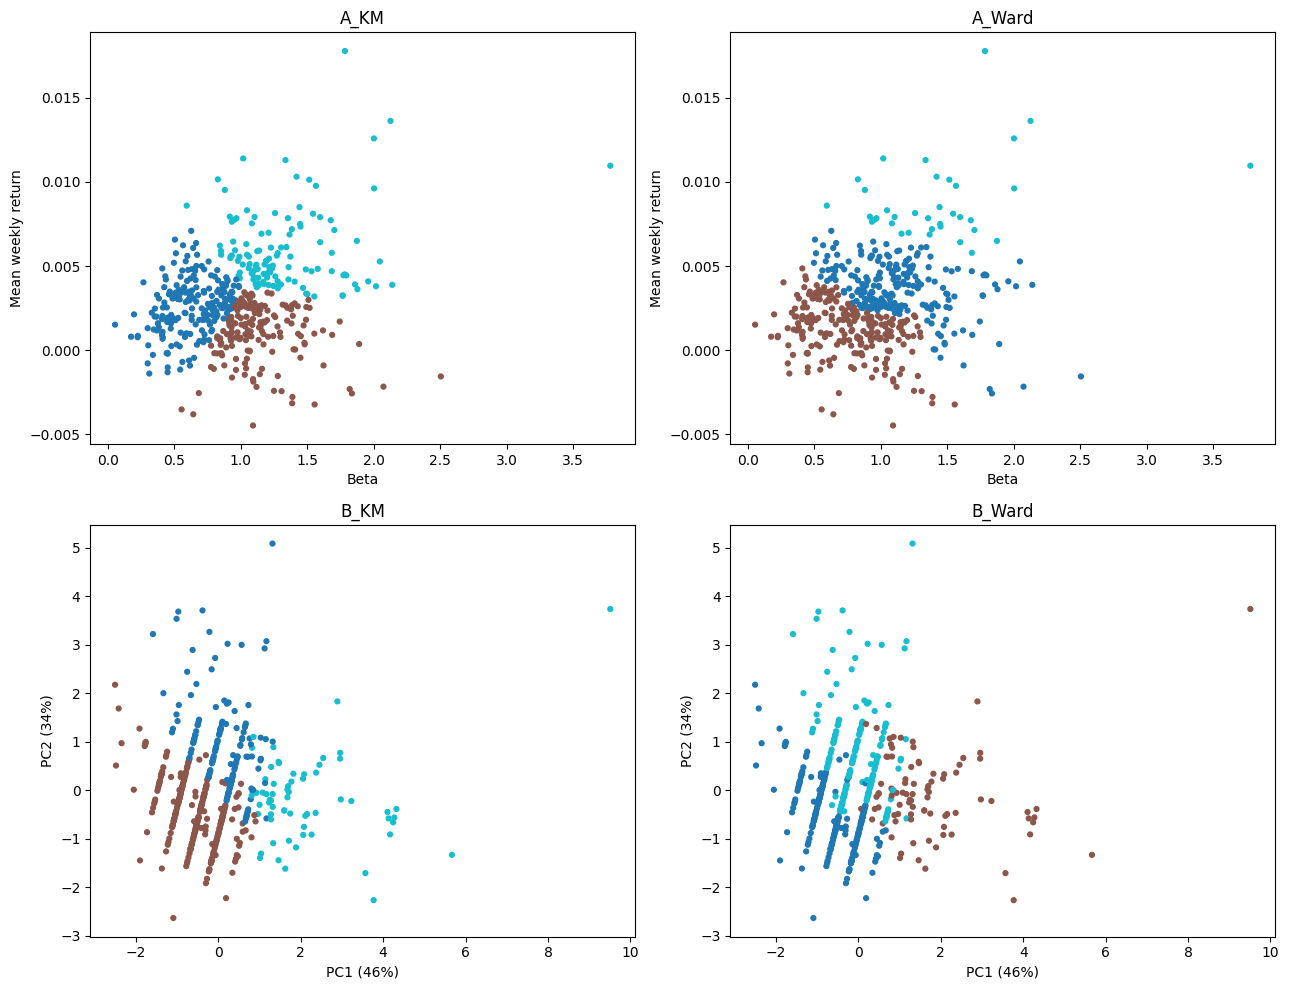

RFM PCA explained variance %: [45.8 33.6]
     Recency  Frequency  logMonetary
PC1     0.71      -0.65         0.27
PC2     0.02       0.40         0.91


In [ ]:
# Cell 15 — labelled 2D visualisation  [brief 2.4; A is already 2D, B needs PCA]
from sklearn.decomposition import PCA

fig, ax = plt.subplots(2, 2, figsize=(13, 10))
for a, col in zip(ax[0], ['A_KM', 'A_Ward']):            # Matrix A: native units, no reduction
    a.scatter(orig.loc[common,'Beta'], orig.loc[common,'MeanWeeklyReturn'],
              c=labels[col], cmap='tab10', s=12)
    a.set(xlabel='Beta', ylabel='Mean weekly return', title=col)

pcaB = PCA(n_components=2, random_state=42).fit(B.values)  # Matrix B: 3D -> 2D
PB, evr = pcaB.transform(B.values), pcaB.explained_variance_ratio_
for a, col in zip(ax[1], ['B_KM', 'B_Ward']):
    a.scatter(PB[:,0], PB[:,1], c=labels[col], cmap='tab10', s=12)
    a.set(xlabel=f'PC1 ({evr[0]*100:.0f}%)', ylabel=f'PC2 ({evr[1]*100:.0f}%)', title=col)
plt.tight_layout(); plt.savefig('cluster_viz.png', dpi=150); plt.show()

print('RFM PCA explained variance %:', (evr*100).round(1))
print(pd.DataFrame(pcaB.components_, columns=['Recency','Frequency','logMonetary'],
                   index=['PC1','PC2']).round(2))

In [ ]:
# Cell 16 — quantify how much the two algorithms agree  [brief 2.4]
from sklearn.metrics import adjusted_rand_score
print('Risk/return  KM vs Ward  ARI:', round(adjusted_rand_score(labels['A_KM'], labels['A_Ward']), 3))
print('RFM          KM vs Ward  ARI:', round(adjusted_rand_score(labels['B_KM'], labels['B_Ward']), 3))
print('\nRFM  K-Means (rows) vs Ward (cols):')
print(pd.crosstab(labels['B_KM'], labels['B_Ward']))

Risk/return  KM vs Ward  ARI: 0.151
RFM          KM vs Ward  ARI: 0.638

RFM  K-Means (rows) vs Ward (cols):
B_Ward    0   1    2
B_KM                
0         0  11  140
1       223  12   40
2         0  63    0


In [ ]:
# Cell 17 — correlation among the RFM clustering inputs  [brief 2.5.1]
corr_feats = rfm.loc[common, ['Recency','Frequency','Monetary']].copy()
corr_feats['Monetary'] = np.log1p(corr_feats['Monetary'])
corr_feats.columns = ['Recency','Frequency','logMonetary']
print(corr_feats.corr().round(3))

             Recency  Frequency  logMonetary
Recency        1.000     -0.346        0.153
Frequency     -0.346      1.000        0.013
logMonetary    0.153      0.013        1.000


In [ ]:
# Cell 18 — remove Monetary, re-cluster on R & F only, compare with ARI  [brief 2.5.2]
# Same shares, same k, Ward; standardise the REDUCED matrix afresh
RF = StandardScaler().fit_transform(rfm.loc[common, ['Recency','Frequency']])
ward_RF = AgglomerativeClustering(K_B, linkage='ward').fit_predict(RF)

print('ARI  full-RFM Ward  vs  R,F-only Ward:',
      round(adjusted_rand_score(labels['B_Ward'], ward_RF), 3))
print('\nCrosstab (full RFM rows vs R,F-only cols):')
print(pd.crosstab(labels['B_Ward'], pd.Series(ward_RF, index=common, name='RF_only')))

# Does Monetary mainly separate activity or liquidity levels?
tv = orig.loc[common, ['Monetary']].copy()
tv['full_RFM'] = labels['B_Ward'].values
tv['RF_only']  = ward_RF
print('\nMean Monetary by full-RFM cluster:\n', tv.groupby('full_RFM')['Monetary'].mean().round(0))
print('\nMean Monetary by R,F-only cluster:\n', tv.groupby('RF_only')['Monetary'].mean().round(0))

ARI  full-RFM Ward  vs  R,F-only Ward: 0.268

Crosstab (full RFM rows vs R,F-only cols):
RF_only   0    1   2
B_Ward              
0         5  152  66
1        84    2   0
2         1  120  59

Mean Monetary by full-RFM cluster:
 full_RFM
0    1.101312e+10
1    4.824805e+10
2    6.993615e+10
Name: Monetary, dtype: float64

Mean Monetary by R,F-only cluster:
 RF_only
0    4.621541e+10
1    3.920490e+10
2    3.433790e+10
Name: Monetary, dtype: float64


In [ ]:
# Cell 19 — sector composition of the clusters  [needed for brief 3.2.1]
sec = sectors.reindex(common)                      # GICS Sector per share (dash format already)
print('RFM (Ward) clusters by sector share:')
print(pd.crosstab(labels['B_Ward'], sec, normalize='index').round(2).T)
print('\nRisk/return (K-Means) clusters by sector share:')
print(pd.crosstab(labels['A_KM'], sec, normalize='index').round(2).T)

RFM (Ward) clusters by sector share:
B_Ward                     0     1     2
GICS Sector                             
Communication Services  0.04  0.02  0.06
Consumer Discretionary  0.07  0.12  0.12
Consumer Staples        0.06  0.07  0.07
Energy                  0.03  0.02  0.07
Financials              0.16  0.15  0.14
Health Care             0.13  0.08  0.13
Industrials             0.19  0.10  0.16
Information Technology  0.09  0.23  0.18
Materials               0.05  0.09  0.02
Real Estate             0.11  0.00  0.03
Utilities               0.08  0.10  0.02

Risk/return (K-Means) clusters by sector share:
A_KM                       0     1     2
GICS Sector                             
Communication Services  0.05  0.02  0.04
Consumer Discretionary  0.05  0.11  0.15
Consumer Staples        0.13  0.03  0.01
Energy                  0.06  0.00  0.07
Financials              0.17  0.16  0.11
Health Care             0.14  0.16  0.02
Industrials             0.13  0.17  0.21
Information 

In [ ]:
# Cell 20 — required deliverable: one row per share, all features + 4 cluster labels
master = orig.copy()
master['Sector'] = sectors.reindex(common)
master = master.join(labels)                       # A_KM, A_Ward, B_KM, B_Ward
master.to_csv('cwk1_feature_cluster_table.csv')
print('Saved', master.shape, 'to cwk1_feature_cluster_table.csv')
master.head()

Saved (489, 10) to cwk1_feature_cluster_table.csv


,MeanWeeklyReturn,Beta,Recency,Frequency,Monetary,Sector,A_KM,A_Ward,B_KM,B_Ward
Share,,,,,,,,,,
A,0.001121,1.074724,11,2,1.400180e+10,Health Care,1,1,1,0
AAPL,0.003930,1.174836,11,2,6.233034e+11,Information Technology,2,0,0,2
ABBV,0.003749,0.425365,11,3,6.837054e+10,Health Care,0,1,0,2
ABNB,0.001475,1.472709,11,3,3.652850e+10,Consumer Discretionary,1,0,0,2
ABT,0.000971,0.583543,11,1,3.523027e+10,Health Care,0,1,0,2
